# Simple Event Log Analysis
Basic statistics for the event log presented in Section "2.2 Basic Analysis".

The original log is only used to check start/completion events and to filter it down to
**complete cases**. All metrics in Section 5 are computed on the filtered log of complete cases.
Section 6 then collapses every work item to a single event for model discovery.

## 1. Imports and Settings

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.load import load_events, build_cases
from src.preprocessing import case_start_activities, completion_activity_counts, filter_complete_cases, collapse_workitems
from src.config import CASE_ID, ACTIVITY, RESOURCE, LIFECYCLE, WORKITEM_PREFIX, START_ACTIVITIES, COMPLETION_ACTIVITIES

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 4)

## 2. Load Data (original log)

In [2]:
events = load_events()
cases = build_cases(events)
cases.head()

,case:RequestedAmount,case:ApplicationType,case:LoanGoal,start,end,duration,length,variant
case:concept:name,,,,,,,,
Application_1000086665,5000.0,New credit,"Other, see explanation",2016-08-03 15:57:21.673+00:00,2016-09-05 06:00:36.893+00:00,32 days 14:03:15.220000,22,"(A_Create Application, A_Submitted, W_Handle l..."
Application_1000158214,12500.0,New credit,Home improvement,2016-06-02 10:14:26.844+00:00,2016-06-10 11:02:01.282+00:00,8 days 00:47:34.438000,25,"(A_Create Application, A_Submitted, W_Handle l..."
Application_1000311556,45000.0,New credit,Car,2016-04-04 15:56:37.675+00:00,2016-05-05 06:00:48.963+00:00,30 days 14:04:11.288000,18,"(A_Create Application, W_Complete application,..."
Application_1000334415,5000.0,New credit,"Other, see explanation",2016-09-15 16:39:17.758+00:00,2016-09-29 07:45:34.389+00:00,13 days 15:06:16.631000,40,"(A_Create Application, A_Submitted, W_Handle l..."
Application_1000339879,37500.0,New credit,Existing loan takeover,2016-03-17 12:57:10.159+00:00,2016-03-30 09:11:48.600+00:00,12 days 20:14:38.441000,51,"(A_Create Application, A_Submitted, W_Handle l..."


## 3. Start and Completion Events (original log)
Frequency of the first activity per case. The expected start activity is `A_Create Application`.

A case counts as complete if it contains at least one of the completion activities
`A_Pending`, `A_Denied` or `A_Cancelled`.

In [3]:
n_cases = len(cases)
n_events = len(events)

start = case_start_activities(events)
start_counts = start.value_counts()
n_start_activities = len(start_counts)
share_true_start = start.isin(START_ACTIVITIES).mean()
print(f"{n_start_activities} distinct start activities")
print(f"start event: {start.isin(START_ACTIVITIES).sum():,} ({share_true_start:.1%})")

1 distinct start activities
start event: 31,509 (100.0%)


In [4]:
completion = completion_activity_counts(events)
n_distinct = (completion > 0).sum(axis=1)
n_total = completion.sum(axis=1)

completion_stats = pd.concat([
    pd.DataFrame({
        "cases containing": (completion > 0).sum(),
        "total occurrences": completion.sum(),
    }),
    pd.DataFrame({"cases containing": {
        "no completion event": (n_distinct == 0).sum(),
        "multiple distinct completion events": (n_distinct > 1).sum(),
        "same completion event repeated": ((n_distinct == 1) & (n_total > 1)).sum(),
    }}),
])
completion_stats["total occurrences"] = completion_stats["total occurrences"].astype("Int64")
completion_stats["share of cases"] = (completion_stats["cases containing"] / n_cases).map("{:.1%}".format)
share_true_completion = (n_distinct > 0).mean()

multi = completion[n_distinct > 1] > 0
if len(multi):
    print("Combinations in cases with multiple distinct completion events:")
    print(multi.apply(lambda r: " + ".join(r.index[r]), axis=1).value_counts().to_string(), "\n")

completion_stats

,cases containing,total occurrences,share of cases
A_Cancelled,10431,10431,33.1%
A_Denied,3752,3753,11.9%
A_Pending,17228,17228,54.7%
no completion event,98,<NA>,0.3%
multiple distinct completion events,0,<NA>,0.0%
same completion event repeated,1,<NA>,0.0%


## 4. Filter Complete Cases
Keep only cases that start with the start activity and contain exactly one completion event
(`A_Pending`, `A_Denied`, `A_Cancelled`).

In [5]:
events_complete = filter_complete_cases(events)
cases_complete = build_cases(events_complete)

n_cases_complete = len(cases_complete)
n_events_complete = len(events_complete)
print(f"Cases:  {n_cases_complete:,} of {n_cases:,} kept ({n_cases_complete / n_cases:.1%}), "
      f"{n_cases - n_cases_complete:,} removed")
print(f"Events: {n_events_complete:,} of {n_events:,} kept ({n_events_complete / n_events:.1%})")

(completion_activity_counts(events_complete) > 0).sum()

Cases:  31,410 of 31,509 kept (99.7%), 99 removed
Events: 1,198,236 of 1,202,267 kept (99.7%)


A_Cancelled    10431
A_Denied        3751
A_Pending      17228
dtype: int64

### Start dates of uncompleted cases

98 uncompleted cases, started 2016-10-24 to 2016-12-31
mean start date (all cases):   2016-07-08 22:53
median start date (all cases): 2016-07-14 11:50
log ends:                      2017-02-01


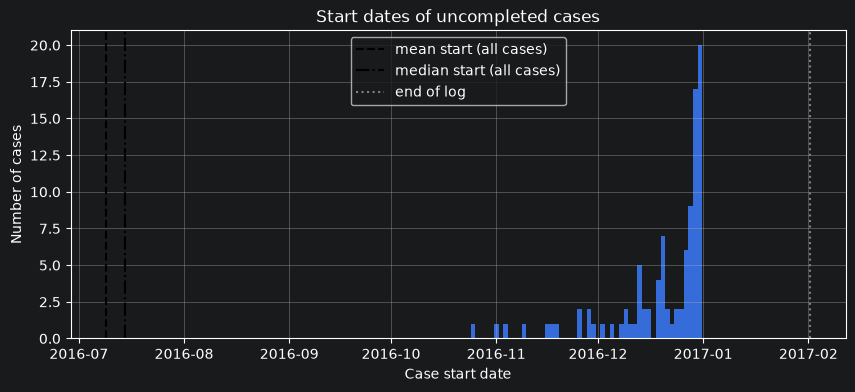

In [6]:
cases_incomplete = cases.loc[n_distinct.index[n_distinct == 0]]
incomplete_start = cases_incomplete["start"]
mean_start_all, median_start_all = cases["start"].mean(), cases["start"].median()
log_end = cases["end"].max()
print(f"{len(cases_incomplete):,} uncompleted cases, started "
      f"{incomplete_start.min():%Y-%m-%d} to {incomplete_start.max():%Y-%m-%d}")
print(f"mean start date (all cases):   {mean_start_all:%Y-%m-%d %H:%M}")
print(f"median start date (all cases): {median_start_all:%Y-%m-%d %H:%M}")
print(f"log ends:                      {log_end:%Y-%m-%d}")

ax = incomplete_start.dt.tz_localize(None).hist(bins=50)
ax.axvline(mean_start_all.tz_localize(None), color="k", linestyle="--", label="mean start (all cases)")
ax.axvline(median_start_all.tz_localize(None), color="k", linestyle="-.", label="median start (all cases)")
ax.axvline(log_end.tz_localize(None), color="grey", linestyle=":", label="end of log")
ax.set(xlabel="Case start date", ylabel="Number of cases", title="Start dates of uncompleted cases")
ax.legend()
plt.show()

## 5. Basic Statistics (complete cases)

### Number of cases

In [7]:
n_cases_complete

31410

### Number of events

In [8]:
n_events_complete

1198236

### Number of process variants

In [9]:
n_variants = cases_complete["variant"].nunique()
n_variants

15843

### Number of distinct case labels

In [10]:
case_attrs = [c.removeprefix("case:") for c in events_complete.columns if c.startswith("case:")]
n_case_attrs = len(case_attrs)
print(f"{n_case_attrs} case attributes:  {case_attrs}")

4 case attributes:  ['concept:name', 'RequestedAmount', 'ApplicationType', 'LoanGoal']


`concept:name` is the case identifier. It is counted as a case attribute but does not actually describe the application.

### Number of distinct event labels

In [11]:
event_attrs = [c for c in events_complete.columns if not c.startswith("case:")]
n_event_attrs = len(event_attrs)
print(f"{n_event_attrs} event attributes: {event_attrs}")

15 event attributes: ['CreditScore', 'MonthlyCost', 'FirstWithdrawalAmount', 'EventID', 'NumberOfTerms', 'concept:name', 'org:resource', 'lifecycle:transition', 'OfferID', 'OfferedAmount', 'Accepted', 'Action', 'Selected', 'EventOrigin', 'time:timestamp']


### Case length (mean and standard deviation)
Case length = number of events per case.

In [12]:
case_length_mean, case_length_std = cases_complete["length"].mean(), cases_complete["length"].std()
print(f"mean = {case_length_mean:.2f} events, \nstandard deviation = {case_length_std:.2f} events")

mean = 38.15 events, 
standard deviation = 16.70 events


### Case duration (mean and standard deviation)
Case duration = time between the first and the last event of a case.

In [13]:
duration_s = cases_complete["duration"].dt.total_seconds()

duration_stats = pd.DataFrame(
    {
        "mean": [duration_s.mean() / 86400, duration_s.mean() / 60, duration_s.mean()],
        "std": [duration_s.std() / 86400, duration_s.std() / 60, duration_s.std()],
    },
    index=["days", "minutes", "seconds"],
)
duration_stats.round(2)

,mean,std
days,21.88,13.13
minutes,31504.69,18911.13
seconds,1890281.49,1134667.60


### Number of categorical event attributes

In [14]:
possible_categorical_event_attrs = [
    c for c in event_attrs
    if not pd.api.types.is_numeric_dtype(events_complete[c])
    and not pd.api.types.is_datetime64_any_dtype(events_complete[c])
]
n_possible_categorical_event_attrs = len(possible_categorical_event_attrs)
print(f"{n_possible_categorical_event_attrs} possible categorical event attributes (neither numeric nor datetime): "
      f"{possible_categorical_event_attrs}")

9 possible categorical event attributes (neither numeric nor datetime): ['EventID', 'concept:name', 'org:resource', 'lifecycle:transition', 'OfferID', 'Accepted', 'Action', 'Selected', 'EventOrigin']


Two out of these 9 are identifiers, not categories, and are excluded: `EventID` and `OfferID`. The remaining 7 are categorical.

In [15]:
identifier_event_attrs = ["EventID", "OfferID"]
categorical_event_attrs = [c for c in possible_categorical_event_attrs if c not in identifier_event_attrs]
n_categorical_event_attrs = len(categorical_event_attrs)
print(f"{n_categorical_event_attrs} categorical event attributes: {categorical_event_attrs}")

7 categorical event attributes: ['concept:name', 'org:resource', 'lifecycle:transition', 'Accepted', 'Action', 'Selected', 'EventOrigin']


### Multiple offers per application
Offers are counted as `O_Create Offer` events per case. Checks whether an application (case) can have more than one offer.

multiple offers per case: yes
8,510 of 31,410 cases with an offer have more than one (27.1%), max 10 offers per case


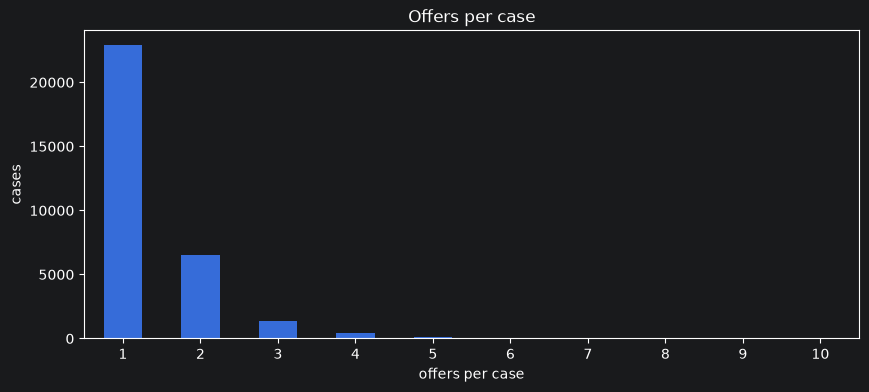

In [16]:
offers = (events_complete.loc[events_complete[ACTIVITY] == "O_Create Offer", CASE_ID]
          .value_counts()
          .reindex(events_complete[CASE_ID].unique(), fill_value=0))
with_offer = offers[offers > 0]
multiple = offers[offers > 1]
print(f"multiple offers per case: {'yes' if len(multiple) else 'no'}")
print(f"{len(multiple):,} of {len(with_offer):,} cases with an offer have more than one "
      f"({len(multiple) / len(with_offer):.1%}), max {offers.max()} offers per case")

ax = offers.value_counts().sort_index().plot.bar(rot=0)
ax.set(xlabel="offers per case", ylabel="cases", title="Offers per case")
plt.show()

### Rare events
Number of cases containing the rare events `W_Shortened completion` and `W_Personal Loan collection` (complete cases).

In [17]:
rare_events = ["W_Shortened completion", "W_Personal Loan collection"]
rare_stats = pd.DataFrame({
    "events": [(events_complete[ACTIVITY] == a).sum() for a in rare_events],
    "cases containing": [events_complete.loc[events_complete[ACTIVITY] == a, CASE_ID].nunique() for a in rare_events],
}, index=rare_events)
rare_stats["share of cases"] = (rare_stats["cases containing"] / n_cases_complete).map("{:.3%}".format)
rare_stats

,events,cases containing,share of cases
W_Shortened completion,238,74,0.236%
W_Personal Loan collection,22,2,0.006%


## 6. Collapse Work Items
Workflow activities are reduced to their `schedule` event.

Withdrawn work items are dropped, since there was no actual work done.

In [18]:
events_collapsed = collapse_workitems(events_complete, drop_withdrawn=True)
cases_collapsed = build_cases(events_collapsed)
cases_collapsed_all = build_cases(collapse_workitems(events_complete))

is_workitem = events_complete[ACTIVITY].str.startswith(WORKITEM_PREFIX)
n_workitems = (is_workitem & (events_complete[LIFECYCLE] == "schedule")).sum()
n_withdrawn = (is_workitem & (events_complete[LIFECYCLE] == "withdraw")).sum()
print(f"{n_workitems:,} work items, {n_withdrawn:,} withdrawn ({n_withdrawn / n_workitems:.1%}) and dropped")

pd.DataFrame({
    "Number of events": [n_events_complete, cases_collapsed_all["length"].sum(), len(events_collapsed)],
    "Case length mean (events)": [round(case_length_mean, 2), round(cases_collapsed_all["length"].mean(), 2),
                                  round(cases_collapsed["length"].mean(), 2)],
    "Number of process variants": [n_variants, cases_collapsed_all["variant"].nunique(),
                                   cases_collapsed["variant"].nunique()],
}, index=["complete cases", "collapsed work items", "collapsed work items, without withdrawn"])

148,549 work items, 21,743 withdrawn (14.6%) and dropped


,Number of events,Case length mean (events),Number of process variants
complete cases,1198236,38.15,15843
collapsed work items,580724,18.49,3347
"collapsed work items, without withdrawn",558981,17.80,3468


### Events before and after collapsing

In [19]:
stages = {
    "Before collapsing (complete cases)": events_complete,
    "After collapsing": collapse_workitems(events_complete),
    "After removing withdrawn": events_collapsed,
}
workitem_table = pd.DataFrame({"Total events": [len(ev) for ev in stages.values()]}, index=list(stages))
workitem_table["Percentage of all events"] = (workitem_table["Total events"] / n_events_complete).map("{:.1%}".format)
workitem_table

,Total events,Percentage of all events
Before collapsing (complete cases),1198236,100.0%
After collapsing,580724,48.5%
After removing withdrawn,558981,46.7%


### Dropped events per workflow activity

In [20]:
def workflow_counts(ev):
    return ev.loc[ev[ACTIVITY].str.startswith(WORKITEM_PREFIX), ACTIVITY].value_counts()

counts = pd.DataFrame({
    "before": workflow_counts(events_complete),
    "collapsed": workflow_counts(stages["After collapsing"]),
    "without withdrawn": workflow_counts(events_collapsed),
}).fillna(0).astype(int)

dropped = pd.DataFrame({
    "Before collapsing": counts["before"],
    "Dropped by collapsing": counts["before"] - counts["collapsed"],
    "Dropped as withdrawn": counts["collapsed"] - counts["without withdrawn"],
})
dropped["Remaining"] = dropped["Before collapsing"] - dropped["Dropped by collapsing"] - dropped["Dropped as withdrawn"]
dropped = dropped.sort_values("Before collapsing", ascending=False)
dropped.loc["Total"] = dropped.sum()
dropped

,Before collapsing,Dropped by collapsing,Dropped as withdrawn,Remaining
concept:name,,,,
W_Validate application,209099,170180,0,38919
W_Call after offers,190540,156073,3140,31327
W_Call incomplete files,167652,144687,0,22965
W_Complete application,148162,116729,1860,29573
W_Handle leads,47066,26704,16740,3622
W_Assess potential fraud,3282,2955,3,324
W_Shortened completion,238,164,0,74
W_Personal Loan collection,22,20,0,2
Total,766061,617512,21743,126806
